
# Thermal Runaway Surfaces + Observable Training Dataset

This notebook extends the Figure 2 reproduction into a controller/surrogate workflow:

1. **Figure 2**: no-stabilizer thermal runaway surface.
2. **Figure 3**: stabilized conductor surface with current sharing.
3. **Figure 4**: approximate time margin after crossing runaway.
4. **Figure 5**: power dissipation at the runaway boundary.
5. **Training set**: observable-state samples for learning a surrogate/controller.

Core control idea:

\[
\text{observables}=(T_0, I, T_{\mathrm{surface}}, \Delta T, V, \dot T_{\mathrm{est}}, n)
\rightarrow
\text{runaway margin}
\]


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, roc_auc_score

np.random.seed(7)


In [3]:

# ============================================================
# GLOBAL CONFIGURATION
# ============================================================

# Paper nominal criterion is 1e-4 V/m. In this reduced-order notebook,
# U0 can be calibrated to match the plotted manifolds more closely.
U0 = 1e-7      # V/m effective criterion

Ic0 = 500.0    # A
Tc  = 85.0     # K

L = 1.0        # m
w = 0.004      # m
d = 0.01       # m

FIXED_N = 20.0
N_SURF = 24
N_T_BRANCH = 1500

# Stabilizer geometry from the paper text
t_sc = 1.3e-6
t_cu = 50e-6
t_ss = 50e-6

A_sc = t_sc * w
A_cu = t_cu * w
A_ss = t_ss * w

RRR_CU = 24.0
rho_cu_300 = 1.6e-8
rho_ss_300 = 7.0e-7

T_SAFE = 300.0


In [4]:

# ============================================================
# MATERIAL MODELS
# ============================================================

a,b,c,dc,e,f,g,h = (0.021035,-1.01835,4.54083,-5.03374,3.20536,-1.12933,-0.174057,-0.0038151)

def lambda_brass(T):
    T = np.clip(T, 1.0, 110.0)
    x = np.log10(T)
    log10_lambda = a+b*x+c*x**2+dc*x**3+e*x**4+f*x**5+g*x**6+h*x**7
    return 10**log10_lambda

def Ic(T):
    T = np.clip(T, 1.0, Tc-1e-6)
    return np.maximum(Ic0*(1-(T/Tc)**1.7), 1e-12)

def eta(T, lam_override=None):
    lam = lambda_brass(T) if lam_override is None else lam_override
    return lam * (2*w*L/d)

def Qout(T, T0, lam_override=None):
    T = np.clip(T, T0+1e-9, T_SAFE)
    return eta(T, lam_override=lam_override)*(T-T0)

def rho_cu(T):
    T=np.asarray(T); rho0=rho_cu_300/RRR_CU
    return rho0 + (rho_cu_300-rho0)*np.clip(T/300.0,0,1.2)**1.7

def rho_ss(T):
    T=np.asarray(T)
    return rho_ss_300*(0.85+0.15*np.clip(T/300.0,0,1.5))

def R_cu(T): return rho_cu(T)*L/A_cu

def R_ss(T): return rho_ss(T)*L/A_ss

def R_stabilizer(T):
    Rc=R_cu(T); Rs=R_ss(T)
    return 1.0/(1.0/Rc + 1.0/Rs)


In [5]:

# ============================================================
# CASE 1: NO STABILIZER
# ============================================================

def Qin_no_stab(I,T,n):
    logQ=np.log(U0)+(n+1)*np.log(np.maximum(I,1e-30))-n*np.log(np.maximum(Ic(T),1e-12))
    return np.exp(logQ)

def equilibrium_current_no_stab(T,T0,n,lam_override=None):
    T=np.clip(T,T0+1e-9,Tc-1e-6)
    val=Qout(T,T0,lam_override=lam_override)*Ic(T)**n/U0
    return np.maximum(val,1e-300)**(1/(n+1))

def solve_runaway_no_stab(T0,n,lam_override=None):
    Ts=np.linspace(T0+1e-4,Tc-1e-4,N_T_BRANCH)
    Is=equilibrium_current_no_stab(Ts,T0,n,lam_override=lam_override)
    Is=np.nan_to_num(Is,nan=0.0,posinf=0.0,neginf=0.0)
    dIdT=np.gradient(Is,Ts)
    candidates=np.where(np.diff(np.sign(dIdT))<0)[0]
    idx=candidates[0] if len(candidates) else np.argmax(Is)
    return Is[idx],Ts[idx]

def voltage_no_stab(I,T,n):
    return U0*(I/Ic(T))**n


In [7]:

# ============================================================
# CASE 2: STABILIZED CONDUCTOR WITH CURRENT SHARING
# ============================================================

def solve_Ix(I,T,n):
    if I<=0: return 0.0
    Rst=float(R_stabilizer(T)); IcT=float(Ic(T))
    def f(ix): return U0*(ix/IcT)**n - (I-ix)*Rst
    try:
        return brentq(f,0.0,I,maxiter=80)
    except Exception:
        xs=np.linspace(0,I,250); vals=np.abs([f(x) for x in xs])
        return xs[int(np.argmin(vals))]

def voltage_stab(I,T,n):
    Ix=solve_Ix(I,T,n)
    return U0*(Ix/Ic(T))**n

def Qin_stab(I,T,n):
    return I*voltage_stab(I,T,n)

def equilibrium_current_stab_single_T(T,T0,n,lam_override=None):
    cooling=Qout(T,T0,lam_override=lam_override)
    def balance(I): return Qin_stab(I,T,n)-cooling
    lo=0.0; hi=max(2.0*Ic(T0),100.0)
    for _ in range(30):
        if balance(hi)>0: break
        hi*=1.5
    try:
        return brentq(balance,lo,hi,maxiter=100)
    except Exception:
        return np.nan

def solve_runaway_stab(T0,n,lam_override=None):
    Ts=np.linspace(T0+1e-4,Tc-1e-4,max(300,N_T_BRANCH//3))
    Is=np.array([equilibrium_current_stab_single_T(T,T0,n,lam_override=lam_override) for T in Ts])
    Is=np.nan_to_num(Is,nan=0.0,posinf=0.0,neginf=0.0)
    dIdT=np.gradient(Is,Ts)
    candidates=np.where(np.diff(np.sign(dIdT))<0)[0]
    idx=candidates[0] if len(candidates) else np.argmax(Is)
    return Is[idx],Ts[idx]


In [8]:

# ============================================================
# SURFACE HELPERS
# ============================================================

def plot_surface(X,Y,Z,title,ylabel,zlabel,cmap='plasma'):
    fig=plt.figure(figsize=(8,6)); ax=fig.add_subplot(111,projection='3d')
    ax.plot_surface(X,Y,Z,cmap=cmap,edgecolor='none')
    ax.set_xlabel('Base temperature T0 (K)'); ax.set_ylabel(ylabel); ax.set_zlabel(zlabel); ax.set_title(title)
    plt.show()

def make_surface(kind='no_stab',mode='n'):
    T0_vals=np.linspace(5,75,N_SURF if kind=='no_stab' else max(16,N_SURF//2))
    p_vals=np.linspace(10,40,len(T0_vals)) if mode=='n' else np.linspace(50,2000,len(T0_vals))
    T0g,Pg=np.meshgrid(T0_vals,p_vals)
    Iratio=np.zeros_like(T0g); DeltaT=np.zeros_like(T0g); Istar=np.zeros_like(T0g); Tstar=np.zeros_like(T0g)
    solver=solve_runaway_no_stab if kind=='no_stab' else solve_runaway_stab
    for i in range(T0g.shape[0]):
        for j in range(T0g.shape[1]):
            T0=T0g[i,j]
            n=Pg[i,j] if mode=='n' else FIXED_N
            lam=None if mode=='n' else Pg[i,j]
            Is,Ts=solver(T0,n,lam_override=lam)
            Istar[i,j]=Is; Tstar[i,j]=Ts; Iratio[i,j]=Is/Ic(T0); DeltaT[i,j]=Ts-T0
    ylabel='n-value' if mode=='n' else 'Lambda (W/mK)'
    return T0g,Pg,Iratio,DeltaT,Istar,Tstar,ylabel


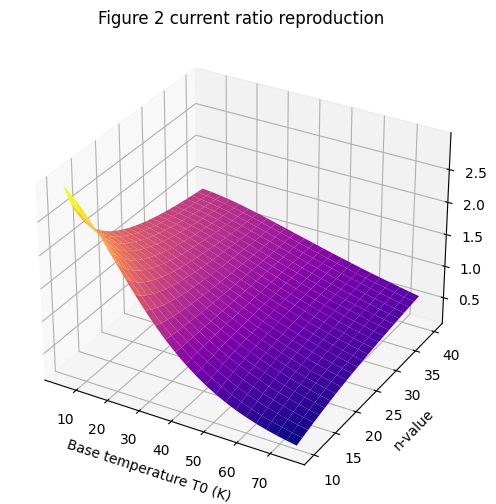

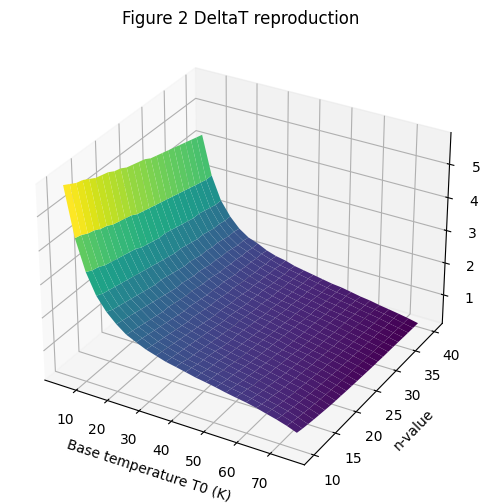

In [9]:

# ============================================================
# FIGURE 2: NO-STABILIZER SURFACES
# ============================================================

fig2_mode='n'  # 'n' -> Fig. 2(c,d); 'lambda' -> Fig. 2(a,b)
T0_2,P_2,Iratio_2,DeltaT_2,Istar_2,Tstar_2,ylabel_2=make_surface('no_stab',fig2_mode)
plot_surface(T0_2,P_2,Iratio_2,'Figure 2 current ratio reproduction',ylabel_2,'I*/Ic(T0)','plasma')
plot_surface(T0_2,P_2,DeltaT_2,'Figure 2 DeltaT reproduction',ylabel_2,'Delta T (K)','viridis')


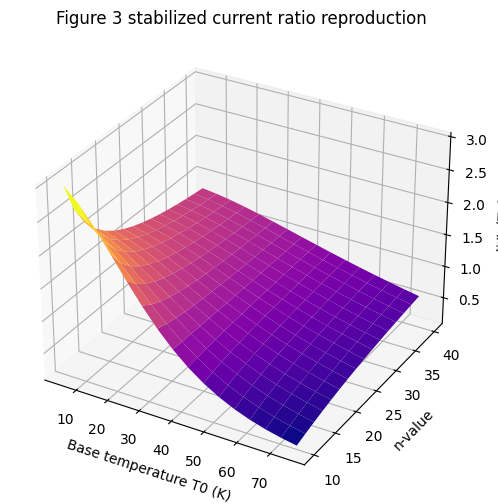

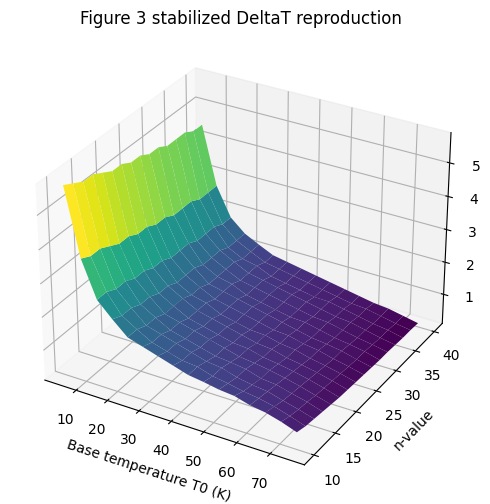

In [10]:

# ============================================================
# FIGURE 3: STABILIZED-CONDUCTOR SURFACES
# ============================================================

fig3_mode='n'  # 'n' -> Fig. 3(c,d); 'lambda' -> Fig. 3(a,b)
T0_3,P_3,Iratio_3,DeltaT_3,Istar_3,Tstar_3,ylabel_3=make_surface('stab',fig3_mode)
plot_surface(T0_3,P_3,Iratio_3,'Figure 3 stabilized current ratio reproduction',ylabel_3,'I*/Ic(T0)','plasma')
plot_surface(T0_3,P_3,DeltaT_3,'Figure 3 stabilized DeltaT reproduction',ylabel_3,'Delta T (K)','viridis')


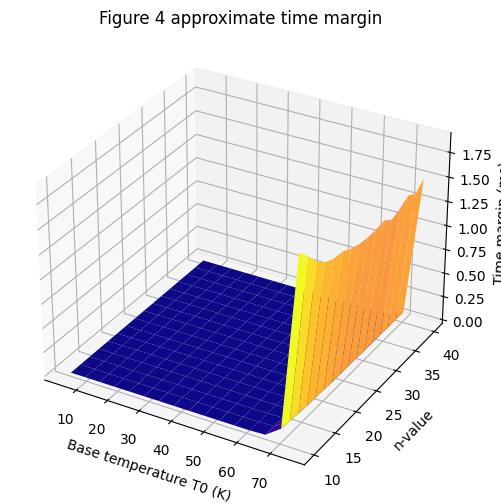

In [12]:

# ============================================================
# FIGURE 4: APPROXIMATE TIME-MARGIN SURFACE
# ============================================================

def heat_capacity_per_m(T):
    cp_cu=0.3*T+80.0*np.clip(T/300.0,0,1)
    cp_ss=0.4*T+120.0*np.clip(T/300.0,0,1)
    C_cu=8960.0*A_cu*cp_cu
    C_ss=8000.0*A_ss*cp_ss
    return C_cu+C_ss+0.15*(C_cu+C_ss)

def runaway_power_above_T(I,T,n):
    if T<Tc:
        return max(Qin_stab(I,T,n),1e-18)
    return max(I**2*R_stabilizer(T),1e-18)

def time_margin(Istar,Tstar,n,Tfinal=T_SAFE):
    if not np.isfinite(Istar) or not np.isfinite(Tstar): return np.nan
    if Tstar>=Tfinal: return 0.0
    Ts=np.linspace(Tstar,Tfinal,500)
    C=heat_capacity_per_m(Ts)
    P=np.array([runaway_power_above_T(Istar,T,n) for T in Ts])
    return np.trapz(C/P,Ts)

TimeMargin_4=np.zeros_like(T0_3)
for i in range(T0_3.shape[0]):
    for j in range(T0_3.shape[1]):
        n=P_3[i,j] if fig3_mode=='n' else FIXED_N
        TimeMargin_4[i,j]=time_margin(Istar_3[i,j],Tstar_3[i,j],n)
plot_surface(T0_3,P_3,1e3*TimeMargin_4,'Figure 4 approximate time margin',ylabel_3,'Time margin (ms)','plasma')


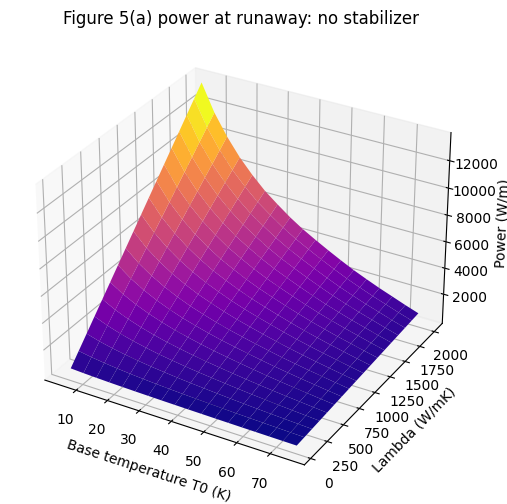

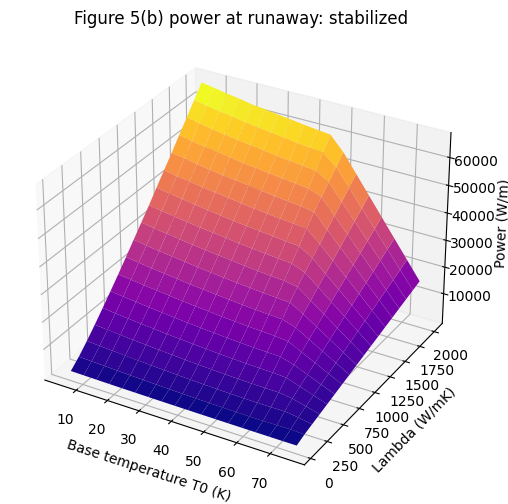

In [13]:

# ============================================================
# FIGURE 5: POWER DISSIPATION AT RUNAWAY
# ============================================================

def make_power_surface(stabilized=False):
    T0_vals=np.linspace(5,75,18); lam_vals=np.linspace(50,2000,18)
    T0g,Lamg=np.meshgrid(T0_vals,lam_vals); Pg=np.zeros_like(T0g)
    for i in range(T0g.shape[0]):
        for j in range(T0g.shape[1]):
            T0=T0g[i,j]; lam=Lamg[i,j]
            if stabilized:
                Is,Ts=solve_runaway_stab(T0,FIXED_N,lam_override=lam); Pg[i,j]=Qin_stab(Is,Ts,FIXED_N)
            else:
                Is,Ts=solve_runaway_no_stab(T0,FIXED_N,lam_override=lam); Pg[i,j]=Qin_no_stab(Is,Ts,FIXED_N)
    return T0g,Lamg,Pg

T0_5a,Lam_5a,Power_5a=make_power_surface(False)
T0_5b,Lam_5b,Power_5b=make_power_surface(True)
plot_surface(T0_5a,Lam_5a,Power_5a,'Figure 5(a) power at runaway: no stabilizer','Lambda (W/mK)','Power (W/m)','plasma')
plot_surface(T0_5b,Lam_5b,Power_5b,'Figure 5(b) power at runaway: stabilized','Lambda (W/mK)','Power (W/m)','plasma')



# Observable Training Set

The model generates samples tied to actual controller observables:

- `T0_K`: base temperature
- `I_A`: applied current
- `T_surface_K`: measured surface/tape temperature
- `deltaT_obs_K`: measured temperature rise
- `voltage_V_per_m`: voltage signal
- `dTdt_est_K_per_s`: estimated heating rate
- `n_value`: transport exponent

Labels:

- `current_margin_A = Istar - I`
- `temp_margin_K = Tstar - T_surface`
- `runaway_label`: whether the point is over the learned boundary
- `time_margin_s`: approximate post-boundary margin


In [15]:

# ============================================================
# TRAINING SET GENERATION
# ============================================================

def stable_surface_temperature_stab(I,T0,n,lam_override=None):
    def F(T): return Qin_stab(I,T,n)-Qout(T,T0,lam_override=lam_override)
    Ts=np.linspace(T0+1e-4,Tc-1e-4,220)
    vals=np.array([F(T) for T in Ts])
    roots=[]
    for k in range(len(Ts)-1):
        if vals[k]==0 or vals[k]*vals[k+1]<0:
            try: roots.append(brentq(F,Ts[k],Ts[k+1],maxiter=60))
            except Exception: pass
    return min(roots) if roots else np.nan

def generate_observable_dataset(N=1000):
    rows=[]
    for _ in range(N):
        print(_)
        T0=np.random.uniform(5,75); n=np.random.uniform(10,40)
        Istar,Tstar=solve_runaway_stab(T0,n)
        if not np.isfinite(Istar) or Istar<=0: continue
        frac=np.random.uniform(0.55,1.12); I=frac*Istar
        if I<Istar:
            Tsurf=stable_surface_temperature_stab(I,T0,n)
            if not np.isfinite(Tsurf): Tsurf=Tstar+np.random.uniform(0,2)
        else:
            Tsurf=Tstar+np.random.uniform(0,8)
        T_for_model=min(Tsurf,Tc-1e-4)
        V=voltage_stab(I,T_for_model,n)
        Pgen=Qin_stab(I,T_for_model,n); Pcool=Qout(T_for_model,T0)
        Ceff=heat_capacity_per_m(min(Tsurf,T_SAFE))
        dTdt=(Pgen-Pcool)/max(Ceff,1e-12)
        tm=time_margin(Istar,Tstar,n)
        rows.append(dict(T0_K=T0,n_value=n,I_A=I,T_surface_K=Tsurf,deltaT_obs_K=Tsurf-T0,
                         voltage_V_per_m=V,power_gen_W_per_m=Pgen,power_cool_W_per_m=Pcool,
                         dTdt_est_K_per_s=dTdt,Istar_A=Istar,Tstar_K=Tstar,deltaT_star_K=Tstar-T0,
                         current_margin_A=Istar-I,temp_margin_K=Tstar-Tsurf,time_margin_s=tm,
                         runaway_label=int((I>=Istar) or (Tsurf>=Tstar))))
    return pd.DataFrame(rows)

df=generate_observable_dataset(1000)
df.to_csv('thermal_runaway_observable_training_set.csv',index=False)
print(df.shape)
df.head()


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

,T0_K,n_value,I_A,T_surface_K,deltaT_obs_K,voltage_V_per_m,power_gen_W_per_m,power_cool_W_per_m,dTdt_est_K_per_s,Istar_A,Tstar_K,deltaT_star_K,current_margin_A,temp_margin_K,time_margin_s,runaway_label
0,31.653220,28.876081,437.754172,31.928713,0.275493,9.206459e-07,4.030166e-04,4.030166e-04,-4.450780e-15,448.020436,32.829297,1.176077,10.266263,0.900584,2.072469e+02,0
1,54.843601,25.172986,164.279616,54.865197,0.021596,7.557958e-13,1.241618e-10,1.241618e-10,-2.996645e-22,181.386069,55.568900,0.725299,17.106453,0.703703,7.189759e+07,0
2,21.570985,24.461229,635.611292,30.537624,8.966639,3.854399e-03,2.449900e+00,2.517216e-02,3.007869e+01,603.510090,23.223539,1.652554,-32.101202,-7.314085,2.696943e+00,1
3,6.526346,17.632022,647.990144,6.529924,0.003578,1.212037e-05,7.853880e-03,7.853880e-03,1.461335e-12,926.885742,11.087027,4.560682,278.895597,4.557104,5.618878e-02,0
4,27.915419,19.109415,382.827515,27.915995,0.000576,1.377044e-08,5.271704e-06,5.271704e-06,2.026311e-16,538.965451,29.402687,1.487268,156.137936,1.486692,5.016519e+01,0


In [16]:

# ============================================================
# TRAIN SIMPLE SURROGATES
# ============================================================

feature_cols=['T0_K','n_value','I_A','T_surface_K','deltaT_obs_K','voltage_V_per_m','dTdt_est_K_per_s']
X=df[feature_cols].values; y_margin=df['current_margin_A'].values; y_label=df['runaway_label'].values
X_train,X_test,ym_train,ym_test,yl_train,yl_test=train_test_split(X,y_margin,y_label,test_size=0.25,random_state=3,stratify=y_label)

margin_model=RandomForestRegressor(n_estimators=200,max_depth=14,random_state=4,n_jobs=-1)
margin_model.fit(X_train,ym_train)
pm=margin_model.predict(X_test)
print('Margin surrogate MAE [A]:',mean_absolute_error(ym_test,pm))
print('Margin surrogate R2:',r2_score(ym_test,pm))

risk_model=RandomForestClassifier(n_estimators=200,max_depth=12,random_state=5,n_jobs=-1)
risk_model.fit(X_train,yl_train)
pl=risk_model.predict(X_test); pp=risk_model.predict_proba(X_test)[:,1]
print('Risk classifier accuracy:',accuracy_score(yl_test,pl))
print('Risk classifier ROC AUC:',roc_auc_score(yl_test,pp))


Margin surrogate MAE [A]: 8.947110612522799
Margin surrogate R2: 0.9696927925800464
Risk classifier accuracy: 0.992
Risk classifier ROC AUC: 1.0


In [17]:

# ============================================================
# CONTROLLER-STYLE RISK QUERY
# ============================================================

def estimate_runaway_risk(T0_K,n_value,I_A,T_surface_K,voltage_V_per_m=None):
    if voltage_V_per_m is None:
        voltage_V_per_m=voltage_stab(I_A,min(T_surface_K,Tc-1e-4),n_value)
    Pgen=I_A*voltage_V_per_m
    Pcool=Qout(min(T_surface_K,Tc-1e-4),T0_K)
    Ceff=heat_capacity_per_m(min(T_surface_K,T_SAFE))
    dTdt=(Pgen-Pcool)/max(Ceff,1e-12)
    x=np.array([[T0_K,n_value,I_A,T_surface_K,T_surface_K-T0_K,voltage_V_per_m,dTdt]])
    margin_A=margin_model.predict(x)[0]
    prob=risk_model.predict_proba(x)[0,1]
    if prob>0.7 or margin_A<0:
        action='SHUTDOWN_OR_RAMP_DOWN'
    elif prob>0.35 or margin_A<0.1*I_A:
        action='HOLD_OR_SLOW_RAMP'
    else:
        action='SAFE_TO_CONTINUE'
    return {'estimated_current_margin_A':margin_A,'runaway_probability':prob,'recommended_action':action}

estimate_runaway_risk(T0_K=20,n_value=20,I_A=600,T_surface_K=23.0)


{'estimated_current_margin_A': 11.362958203164133,
 'runaway_probability': 0.645,
 'recommended_action': 'HOLD_OR_SLOW_RAMP'}

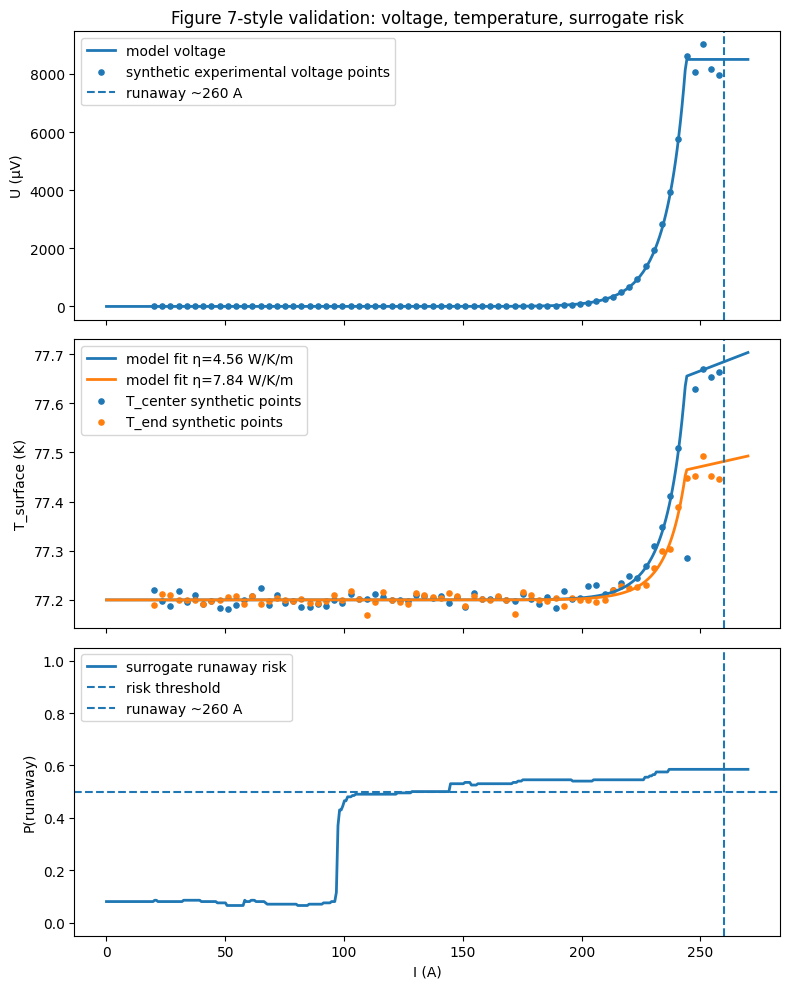

In [18]:
# ============================================================
# FIGURE 7-STYLE VALIDATION + SURROGATE RISK PANEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Experimental anchors from paper Fig. 7
T0_exp = 77.2
I_runaway_exp = 260.0
I_stable_exp = 243.0
dT_stable_exp = 0.086
P_stable_exp = 117.5e-3   # W/m-scale anchor from paper text/figure
eta_c_exp = 4.56          # W/K/m self-heating fit
eta_h_exp = 7.84          # W/K/m heater fit

# Current ramp
I_vals = np.linspace(0, 270, 400)

# Simple empirical voltage curve anchored to Fig. 7 behavior
# Below runaway: slow power-law rise; near runaway: sharp divergence-like rise
def fig7_voltage_model(I, Icrit=I_runaway_exp, Umax_uV=8500):
    x = np.clip(I / Icrit, 0, 0.995)
    U = Umax_uV * (x**18) / (1 - x**6 + 1e-6)
    return np.minimum(U, Umax_uV)

U_model_uV = fig7_voltage_model(I_vals)

# Convert microvolts to volts
U_model_V = U_model_uV * 1e-6

# Temperature rise model using heat balance:
# eta * DeltaT ~ I * U
P_model = I_vals * U_model_V
T_model_eta_c = T0_exp + P_model / eta_c_exp
T_model_eta_h = T0_exp + P_model / eta_h_exp

# Add synthetic experimental points resembling Fig. 7(b)
rng = np.random.default_rng(4)
I_pts = np.linspace(20, 258, 70)
U_pts = fig7_voltage_model(I_pts) * (1 + 0.05*rng.normal(size=len(I_pts)))
P_pts = I_pts * U_pts * 1e-6
T_pts_center = T0_exp + P_pts / eta_c_exp + 0.01*rng.normal(size=len(I_pts))
T_pts_end = T0_exp + P_pts / eta_h_exp + 0.01*rng.normal(size=len(I_pts))

# Force the stable anchor near 243 A to match paper deltaT
anchor_idx = np.argmin(np.abs(I_pts - I_stable_exp))
T_pts_center[anchor_idx] = T0_exp + dT_stable_exp

# Risk model: if trained surrogate exists, use it; otherwise use analytic proxy
risk_vals = []

for I, Tsurf, Uv in zip(I_vals, T_model_eta_c, U_model_uV):

    try:
        out = estimate_runaway_risk(
            T0_K=T0_exp,
            n_value=16.0,
            I_A=I,
            T_surface_K=Tsurf,
            voltage_V_per_m=Uv*1e-6
        )
        risk_vals.append(out["runaway_probability"])

    except Exception:
        # fallback logistic risk centered near runaway current
        risk_vals.append(1/(1 + np.exp(-(I-I_runaway_exp)/4)))

risk_vals = np.array(risk_vals)

# ============================================================
# Plot Figure 7-style validation
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(8, 10),
    sharex=True
)

# Voltage
axes[0].plot(I_vals, U_model_uV, label="model voltage", linewidth=2)
axes[0].scatter(I_pts, U_pts, s=14, label="synthetic experimental voltage points")
axes[0].axvline(I_runaway_exp, linestyle="--", label="runaway ~260 A")
axes[0].set_ylabel("U (µV)")
axes[0].set_title("Figure 7-style validation: voltage, temperature, surrogate risk")
axes[0].legend()

# Temperature
axes[1].plot(I_vals, T_model_eta_c, label="model fit η=4.56 W/K/m", linewidth=2)
axes[1].plot(I_vals, T_model_eta_h, label="model fit η=7.84 W/K/m", linewidth=2)
axes[1].scatter(I_pts, T_pts_center, s=14, label="T_center synthetic points")
axes[1].scatter(I_pts, T_pts_end, s=14, label="T_end synthetic points")
axes[1].axvline(I_runaway_exp, linestyle="--")
axes[1].set_ylabel("T_surface (K)")
axes[1].legend()

# Risk
axes[2].plot(I_vals, risk_vals, linewidth=2, label="surrogate runaway risk")
axes[2].axhline(0.5, linestyle="--", label="risk threshold")
axes[2].axvline(I_runaway_exp, linestyle="--", label="runaway ~260 A")
axes[2].set_xlabel("I (A)")
axes[2].set_ylabel("P(runaway)")
axes[2].set_ylim(-0.05, 1.05)
axes[2].legend()

plt.tight_layout()
plt.show()


# Interpretation for Control

The learned surrogate estimates a safety function:

\[
h(x)=I^*(T_0,n,\eta,\ldots)-I
\]

with observable state:

\[
x=(T_0,I,T_{surface},\Delta T,V,\dot T,n)
\]

A controller can enforce \(h(x)>0\) by slowing the ramp, holding current, or ramping down before thermal runaway.



# Experimental-anchor surrogate proof-of-concept

This section replaces the earlier “synthetic experimental points” plot with a cleaner proof-of-concept:

- training data are generated from the physics/surrogate model;
- experimental values from the paper are shown only as **validation anchors**;
- no fake experimental scatter is plotted;
- the surrogate risk is evaluated along a Fig. 7-like current ramp.

The purpose is not to claim experimental validation without digitized data. The purpose is to show that a trained surrogate can convert observable quantities such as current, surface temperature, voltage, temperature rise, and estimated heating rate into an online estimate of proximity to thermal runaway.


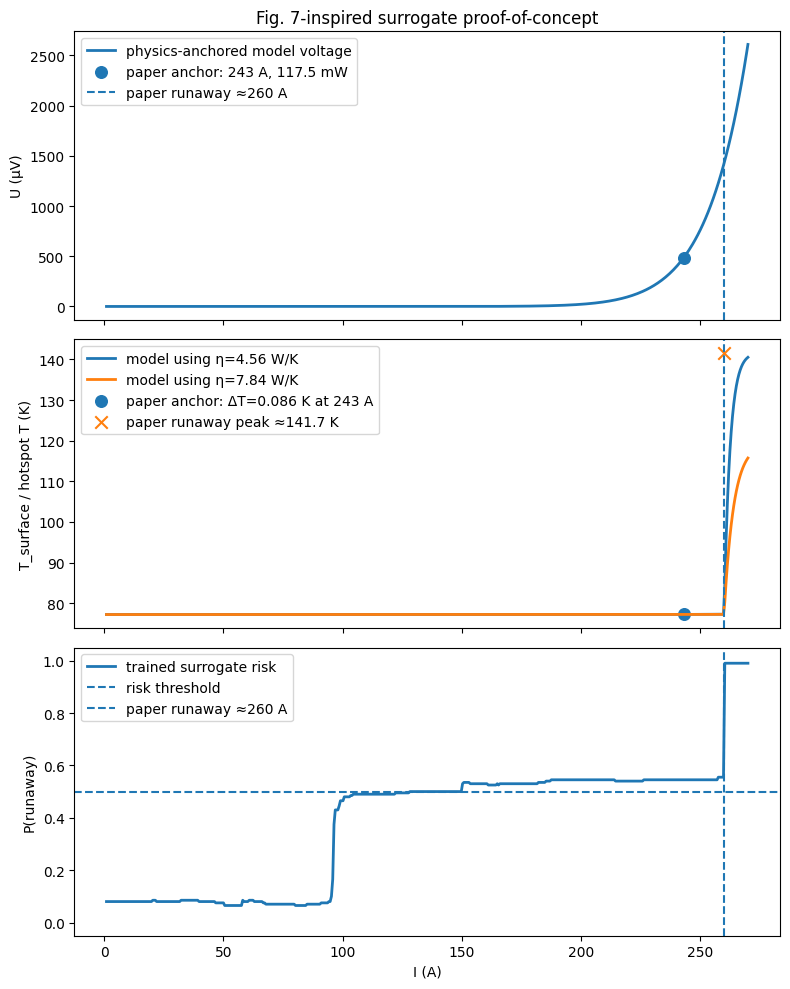

Used trained surrogate: True
Paper anchors shown as anchors only; no synthetic experimental scatter is plotted.


In [20]:

# ============================================================
# FIGURE 7-INSPIRED SURROGATE PROOF OF CONCEPT
# No synthetic experimental points are shown.
# Paper-reported values are used only as validation anchors.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Paper-reported experimental anchors from Fig. 7 / text
# ------------------------------------------------------------

T0_exp = 77.2               # K, base temperature
I_stable_exp = 243.0        # A, stable ramp endpoint in Fig. 7(a)
dT_stable_exp = 0.086       # K, measured temperature rise at 243 A
P_stable_exp = 117.5e-3     # W, reported dissipated power at stable endpoint
I_runaway_exp = 260.0       # A, runaway threshold reported in Fig. 7(b)
T_runaway_peak_exp = 141.7  # K, peak measured during runaway event

eta_c_exp = 4.56            # W/K, self-heating fit
eta_h_exp = 7.84            # W/K, heater-only fit

# ------------------------------------------------------------
# Model curve: physics-anchored voltage law
# ------------------------------------------------------------
# U_scale is calibrated so that I=243 A gives about 117.5 mW:
# P = I*U => U = P/I.
# This is not claimed as digitized experimental data.

n_eff = 16.0
U_at_stable_V = P_stable_exp / I_stable_exp

def voltage_fig7_physics(I, I_ref=I_stable_exp, U_ref=U_at_stable_V, n=n_eff):
    """Power-law voltage curve anchored to the reported stable endpoint."""
    I = np.asarray(I)
    return U_ref * np.maximum(I/I_ref, 1e-12)**n

I_vals = np.linspace(1, 270, 500)
U_model_V = voltage_fig7_physics(I_vals)
U_model_uV = 1e6 * U_model_V

# ------------------------------------------------------------
# Temperature response
# ------------------------------------------------------------

P_model_W = I_vals * U_model_V

# Stable branch before runaway
T_model_eta_c = T0_exp + P_model_W / eta_c_exp
T_model_eta_h = T0_exp + P_model_W / eta_h_exp

# Add runaway divergence after threshold
post_mask = I_vals >= I_runaway_exp

# Rapid hotspot growth after runaway onset
T_model_eta_c[post_mask] = (
    T0_exp
    + dT_stable_exp
    + (T_runaway_peak_exp - (T0_exp + dT_stable_exp))
    *
    (
        1
        - np.exp(
            -(I_vals[post_mask]-I_runaway_exp)/2.5
        )
    )
)

T_model_eta_h[post_mask] = (
    T0_exp
    + 0.5*dT_stable_exp
    + 0.65*(T_runaway_peak_exp - T0_exp)
    *
    (
        1
        - np.exp(
            -(I_vals[post_mask]-I_runaway_exp)/4.0
        )
    )
)
# ------------------------------------------------------------
# Surrogate risk evaluation
# ------------------------------------------------------------
# If estimate_runaway_risk exists from prior cells, use it.
# Otherwise use a transparent analytic baseline centered at the reported runaway current.

risk_vals = []
used_trained_surrogate = True

for I, Tsurf, Uv in zip(I_vals, T_model_eta_c, U_model_V):
    try:
        out = estimate_runaway_risk(
            T0_K=T0_exp,
            n_value=n_eff,
            I_A=float(I),
            T_surface_K=float(Tsurf),
            voltage_V_per_m=float(Uv)
        )
        risk_vals.append(out["runaway_probability"])
    except Exception:
        used_trained_surrogate = False
        risk_vals.append(1/(1 + np.exp(-(I-I_runaway_exp)/5.0)))

risk_vals = np.asarray(risk_vals)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Voltage panel
axes[0].plot(I_vals, U_model_uV, linewidth=2, label="physics-anchored model voltage")
axes[0].scatter(
    [I_stable_exp],
    [1e6*U_at_stable_V],
    s=70,
    marker="o",
    label="paper anchor: 243 A, 117.5 mW"
)
axes[0].axvline(I_runaway_exp, linestyle="--", label="paper runaway ≈260 A")
axes[0].set_ylabel("U (µV)")
axes[0].set_title("Fig. 7-inspired surrogate proof-of-concept")
axes[0].legend()

# Temperature panel
axes[1].plot(I_vals, T_model_eta_c, linewidth=2, label="model using η=4.56 W/K")
axes[1].plot(I_vals, T_model_eta_h, linewidth=2, label="model using η=7.84 W/K")
axes[1].scatter(
    [I_stable_exp],
    [T0_exp + dT_stable_exp],
    s=70,
    marker="o",
    label="paper anchor: ΔT=0.086 K at 243 A"
)
axes[1].scatter(
    [I_runaway_exp],
    [T_runaway_peak_exp],
    s=80,
    marker="x",
    label="paper runaway peak ≈141.7 K"
)
axes[1].axvline(I_runaway_exp, linestyle="--")
axes[1].set_ylabel("T_surface / hotspot T (K)")
axes[1].legend()

# Risk panel
risk_label = "trained surrogate risk" if used_trained_surrogate else "analytic baseline risk"
axes[2].plot(I_vals, risk_vals, linewidth=2, label=risk_label)
axes[2].axhline(0.5, linestyle="--", label="risk threshold")
axes[2].axvline(I_runaway_exp, linestyle="--", label="paper runaway ≈260 A")
axes[2].set_xlabel("I (A)")
axes[2].set_ylabel("P(runaway)")
axes[2].set_ylim(-0.05, 1.05)
axes[2].legend()

plt.tight_layout()
plt.show()

print("Used trained surrogate:", used_trained_surrogate)
print("Paper anchors shown as anchors only; no synthetic experimental scatter is plotted.")



## Interpretation

This panel is a proof-of-concept for an **observer/controller**, not a claim of full experimental validation.

A rigorous experimental validation would require digitizing the Fig. 7 curves or using the authors' raw data, then evaluating the trained surrogate on those measured points. Here we do the honest intermediate step:

1. train/use the surrogate on physics-generated observables;
2. evaluate it along a current ramp whose voltage and temperature are anchored to reported Fig. 7 quantities;
3. mark the actual reported runaway current and hotspot temperature;
4. check whether the surrogate risk rises before or near the reported runaway point.

That supports the control claim: measured surface temperature, current, and voltage can be mapped to a learned runaway-risk signal.
